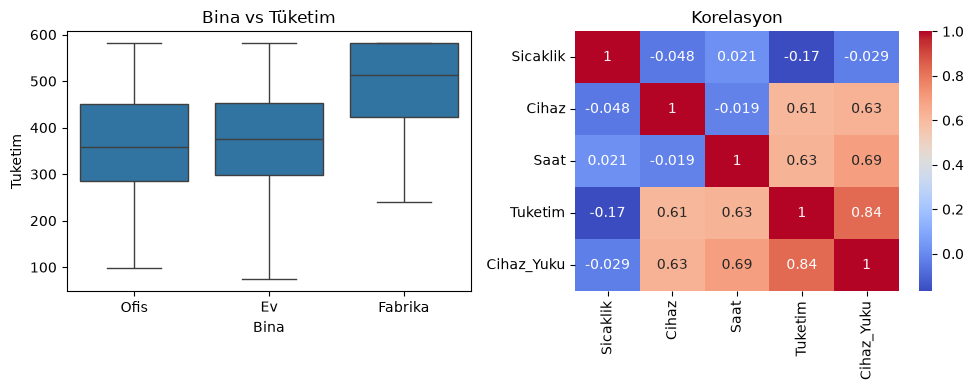

R2 Başarı: 0.96 | MAE: 16.96 | RMSE: 22.44


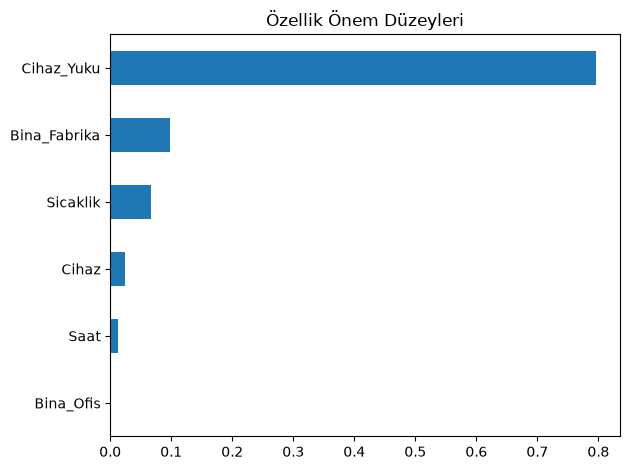

In [ ]:
import sqlite3, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.preprocessing import RobustScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
np.random.seed(42)

n = 1000
df = pd.DataFrame({
    "Sicaklik": np.round(np.random.uniform(-5, 38, n), 1),
    "Cihaz": np.random.randint(3, 25, n),
    "Saat": np.round(np.random.uniform(1, 16, n), 1),
    "Bina": np.random.choice(["Ev", "Ofis", "Fabrika"], n, p=[0.6, 0.3, 0.1])
})

df["Tuketim"] = (
    (df["Cihaz"] * 12) +
    (df["Saat"] * 18) +
    (np.abs(df["Sicaklik"] - 21) * 5) +
    (df["Bina"] == "Fabrika") * 150 +
    np.random.normal(0, 10, n)
)
df.loc[0:20, "Sicaklik"] = np.nan

conn = sqlite3.connect("enerji.db")
df.to_sql("veriler", conn, if_exists="replace", index=False)
df = pd.read_sql_query("SELECT * FROM veriler", conn)
conn.close()


df["Sicaklik"] = df["Sicaklik"].fillna(df["Sicaklik"].median())
df["Tuketim"] = np.clip(df["Tuketim"], None, df["Tuketim"].quantile(0.95))
df["Cihaz_Yuku"] = df["Cihaz"] * df["Saat"]


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
sns.boxplot(data=df, x="Bina", y="Tuketim", ax=ax1).set_title("Bina vs Tüketim")
sns.heatmap(df.select_dtypes(include=np.number).corr(), annot=True, cmap="coolwarm", ax=ax2).set_title("Korelasyon")
plt.tight_layout()
plt.show()


df = pd.get_dummies(df, columns=["Bina"], drop_first=True)
X, y = df.drop("Tuketim", axis=1), df["Tuketim"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = RobustScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

ayarlar = dict(n_estimators=list((50, 100)), max_depth=list((4, 8)))
grid = GridSearchCV(RandomForestRegressor(random_state=42), ayarlar, cv=KFold(5, shuffle=True, random_state=42), scoring="r2")
grid.fit(X_train, y_train)


model = grid.best_estimator_
tahmin = model.predict(X_test)
rmse = np.sqrt(mean_squared_error(y_test, tahmin))
print(f"R2 Başarı: {r2_score(y_test, tahmin):.2f} | MAE: {mean_absolute_error(y_test, tahmin):.2f} | RMSE: {rmse:.2f}")

pd.Series(model.feature_importances_, index=X.columns).sort_values().plot(kind="barh", title="Özellik Önem Düzeyleri")
plt.tight_layout()
plt.show()
